<a href="https://colab.research.google.com/github/ababilkhoerulimam/text-processing-week4/blob/main/ababil%20bethania_exercise%207.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Exercise 7 - Text Similarity

**Chapter 7 - Text Similarity**

Anggota Kelompok (2 mahasiswa):
1. Ababil Khoerul Imam - 152
2. Bethania Putri Junjungsari Nugraha - 115

**Deskripsi Tugas:**
Menerapkan teknik text similarity pada dataset Hacker News hasil preprocessing Exercise 4 (kolom `prepro`) dan menganalisis performa representasi:
1. Jaccard Similarity (metrik himpunan leksikal berdasar Intersection over Union)
2. Cosine Similarity berbasis Bag of Words (CountVectorizer)
3. Cosine Similarity berbasis TF-IDF (TfidfVectorizer)
4. Perbandingan Jaccard Distance vs Cosine Distance
5. Pencarian Dokumen Relevan (Information Retrieval Top-K) berdasarkan kueri teks
6. Analisis korelasi dan perbandingan karakteristik metrik kemiripan

## 0. Persiapan Lingkungan dan Import Library

Library yang digunakan:
- `pandas` dan `numpy` untuk manipulasi data tabel dan komputasi matriks
- `matplotlib.pyplot` untuk visualisasi matriks dan distribusi nilai kemiripan
- `scikit-learn` untuk ekstraksi fitur (CountVectorizer, TfidfVectorizer) dan komputasi cosine similarity
- `scipy.spatial.distance` untuk komputasi jarak pasangan objek

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity, cosine_distances
from scipy.spatial.distance import pdist, squareform

pd.set_option('display.max_columns', 10)
pd.set_option('display.width', 120)
print('Library berhasil diimpor.')

Library berhasil diimpor.


## 1. Memuat Dataset Hacker News Terpraproses

Dataset yang digunakan adalah `hackernews_preprocessed.csv` yang memuat teks artikel yang telah melewati tahap pembersihan, tokenisasi, stopword removal, dan lemmatization/stemming pada kolom `prepro`.

In [2]:
df = pd.read_csv('hackernews_preprocessed.csv')
df = df.dropna(subset=['prepro']).reset_index(drop=True)
print(f'Total baris data: {len(df)}')
df[['id', 'title', 'prepro']].head(10)

Total baris data: 30


,id,title,prepro
0,49906637,Pi.dev: You Said No MCP,pi dev said mcp
1,49908962,SDF vs. MSDF vs. Slug: GPU Text Rendering,sdf vs msdf vs slug gpu text render
2,49890707,Show HN: JBR-001 – An open-source 3D printable...,show hn jbr 001 open sourc 3d printabl desktop...
3,49901736,Livenerf: Has Opus 5.5 been nerfed yet?,livenerf opu 5 5 nerf yet
4,49889140,Mathematical Origami,mathemat origami
5,49883970,I Could've Accessed 17T Microsoft Records,could access 17t microsoft record
6,49887343,Solving Factorio Quality,solv factorio qualiti
7,49879346,Getting out of the way: my robotics crash course,get way robot crash cours
8,49896604,Dots: Always-on agents,dot alway agent
9,49897993,Vermont replacing power plants with home batte...,vermont replac power plant home batteri


## 2. Uji Coba Konseptual pada Dokumen Mini

Sebelum diterapkan ke dataset utuh, berikut simulasi konseptual sesuai contoh materi kuliah (Chapter 7):
- Dokumen 0: `text data clustering`
- Dokumen 1: `text mining and data analysis`
- Dokumen 2: `clustering and classification`

Dua metrik utama yang dibandingkan:
1. **Cosine Similarity**: Mengukur sudut antar vektor frekuensi kata.
$$\text{Cosine}(A, B) = \frac{A \cdot B}{\|A\| \|B\|}$$
2. **Jaccard Similarity**: Mengukur rasio irisan kata unik terhadap gabungan kata unik.
$$J(A, B) = \frac{|A \cap B|}{|A \cup B|}$$

In [3]:
toy_docs = [
    'text data clustering',
    'text mining and data analysis',
    'clustering and classification'
]

def jaccard_similarity_text(doc1, doc2):
    set1 = set(doc1.split())
    set2 = set(doc2.split())
    intersection = len(set1.intersection(set2))
    union = len(set1.union(set2))
    return intersection / union if union > 0 else 0.0

# Vektorisasi Bag of Words
toy_cv = CountVectorizer()
toy_bow = toy_cv.fit_transform(toy_docs).toarray()
toy_cosine = cosine_similarity(toy_bow)

# Matriks Jaccard
n_toy = len(toy_docs)
toy_jaccard = np.zeros((n_toy, n_toy))
for i in range(n_toy):
    for j in range(n_toy):
        toy_jaccard[i, j] = jaccard_similarity_text(toy_docs[i], toy_docs[j])

df_toy_cosine = pd.DataFrame(np.round(toy_cosine, 3), index=[f'Doc_{i}' for i in range(n_toy)], columns=[f'Doc_{i}' for i in range(n_toy)])
df_toy_jaccard = pd.DataFrame(np.round(toy_jaccard, 3), index=[f'Doc_{i}' for i in range(n_toy)], columns=[f'Doc_{i}' for i in range(n_toy)])

print('Matriks Cosine Similarity (BoW):')
print(df_toy_cosine)
print('\nMatriks Jaccard Similarity:')
print(df_toy_jaccard)

Matriks Cosine Similarity (BoW):
       Doc_0  Doc_1  Doc_2
Doc_0  1.000  0.516  0.333
Doc_1  0.516  1.000  0.258
Doc_2  0.333  0.258  1.000

Matriks Jaccard Similarity:
       Doc_0  Doc_1  Doc_2
Doc_0  1.000  0.333  0.200
Doc_1  0.333  1.000  0.143
Doc_2  0.200  0.143  1.000


## 3. Implementasi Text Similarity pada Dataset Hacker News

Pada bagian ini kita menghitung similarity matriks antar 30 artikel Hacker News menggunakan 3 metode:
1. **Jaccard Similarity** (berdasarkan token set leksikal)
2. **Cosine Similarity Bag of Words** (berdasarkan frekuensi kemunculan kata CountVectorizer)
3. **Cosine Similarity TF-IDF** (berdasarkan bobot kepentingan term TfidfVectorizer)

In [4]:
corpus = df['prepro'].tolist()
n_samples = len(corpus)

# 1. Matriks Jaccard Similarity
jaccard_matrix = np.zeros((n_samples, n_samples))
for i in range(n_samples):
    for j in range(n_samples):
        jaccard_matrix[i, j] = jaccard_similarity_text(corpus[i], corpus[j])

# 2. Matriks Cosine BoW
cv = CountVectorizer()
bow_matrix = cv.fit_transform(corpus)
cosine_bow_matrix = cosine_similarity(bow_matrix)

# 3. Matriks Cosine TF-IDF
tfidf = TfidfVectorizer()
tfidf_matrix = tfidf.fit_transform(corpus)
cosine_tfidf_matrix = cosine_similarity(tfidf_matrix)

print(f'Dimensi korpus: {n_samples} dokumen')
print(f'Ukuran kosakata BoW & TF-IDF: {len(cv.get_feature_names_out())} token unik')
print('Perhitungan 3 matriks similarity selesai.')

Dimensi korpus: 30 dokumen
Ukuran kosakata BoW & TF-IDF: 163 token unik
Perhitungan 3 matriks similarity selesai.


### Visualisasi Matriks Kemiripan

Perbandingan visual distribusi nilai kemiripan pada heatmap di bawah memperlihatkan tingkat sparsity dan magnitudo skor antar metode.

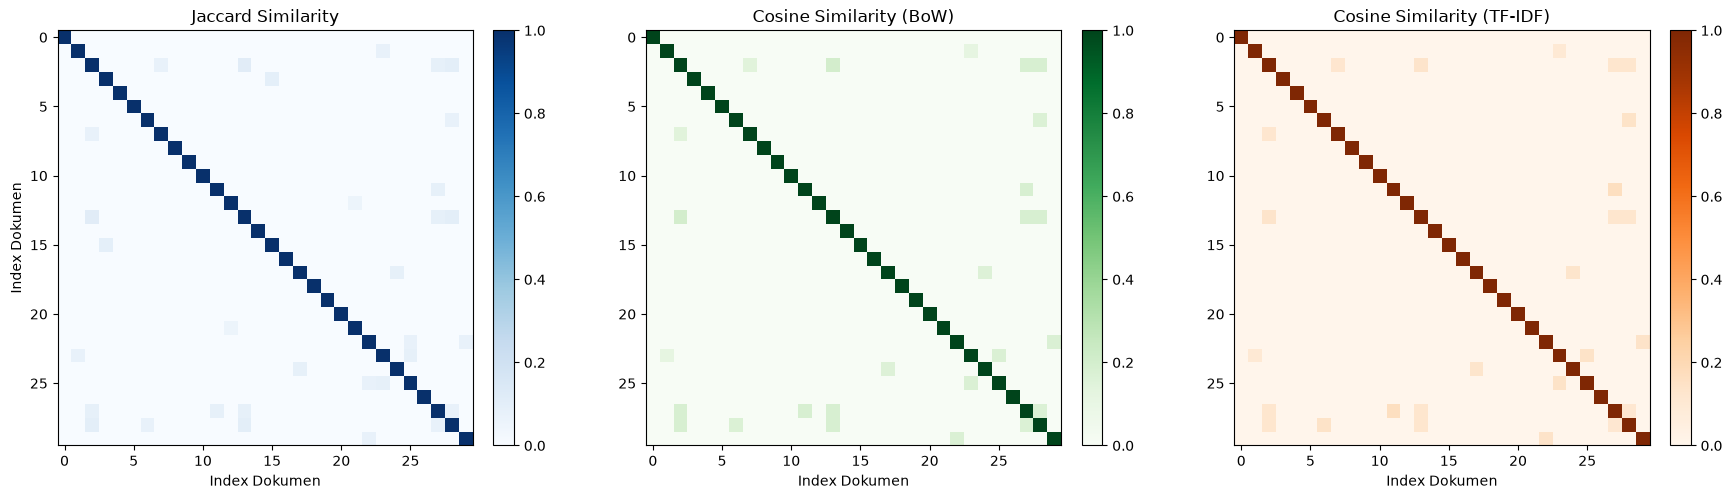

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(jaccard_matrix, cmap='Blues', vmin=0, vmax=1)
axes[0].set_title('Jaccard Similarity')
axes[0].set_xlabel('Index Dokumen')
axes[0].set_ylabel('Index Dokumen')
plt.colorbar(im0, ax=axes[0], fraction=0.046, pad=0.04)

im1 = axes[1].imshow(cosine_bow_matrix, cmap='Greens', vmin=0, vmax=1)
axes[1].set_title('Cosine Similarity (BoW)')
axes[1].set_xlabel('Index Dokumen')
plt.colorbar(im1, ax=axes[1], fraction=0.046, pad=0.04)

im2 = axes[2].imshow(cosine_tfidf_matrix, cmap='Oranges', vmin=0, vmax=1)
axes[2].set_title('Cosine Similarity (TF-IDF)')
axes[2].set_xlabel('Index Dokumen')
plt.colorbar(im2, ax=axes[2], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

## 4. Sistem Pencarian Dokumen Relevan (Information Retrieval Top-K)

Simulasi sistem penelusuran informasi: pengguna memasukkan kueri teks baru, kemudian sistem menghitung kemiripan kueri terhadap setiap dokumen dalam korpus dan menampilkan dokumen paling relevan (Top-5).

In [6]:
def retrieve_similar_articles(query_text, top_k=5):
    # 1. Transformasi kueri ke TF-IDF
    query_vec = tfidf.transform([query_text])
    cos_scores = cosine_similarity(query_vec, tfidf_matrix).flatten()
    
    # 2. Hitung Jaccard similarity kueri ke setiap dokumen
    jac_scores = np.array([jaccard_similarity_text(query_text, doc) for doc in corpus])
    
    results = []
    for idx in range(len(corpus)):
        results.append({
            'doc_index': idx,
            'title': df.loc[idx, 'title'],
            'prepro': df.loc[idx, 'prepro'],
            'cosine_tfidf': cos_scores[idx],
            'jaccard': jac_scores[idx]
        })
    
    res_df = pd.DataFrame(results)
    # Urutkan berdasarkan Cosine TF-IDF tertinggi
    res_sorted = res_df.sort_values(by='cosine_tfidf', ascending=False).head(top_k).reset_index(drop=True)
    return res_sorted

# Pengujian Kueri 1: Topik Robotik / Perangkat Keras
query_1 = 'open sourc 3d printabl robot desktop'
print(f'Hasil Pencarian Kueri 1: "{query_1}"')
top_q1 = retrieve_similar_articles(query_1, top_k=5)
print(top_q1[['doc_index', 'title', 'cosine_tfidf', 'jaccard']])

Hasil Pencarian Kueri 1: "open sourc 3d printabl robot desktop"
   doc_index                                              title  cosine_tfidf  jaccard
0          2  Show HN: JBR-001 – An open-source 3D printable...      0.801143      0.6
1          7   Getting out of the way: my robotics crash course      0.150811      0.1
2          1          SDF vs. MSDF vs. Slug: GPU Text Rendering      0.000000      0.0
3          3            Livenerf: Has Opus 5.5 been nerfed yet?      0.000000      0.0
4          4                               Mathematical Origami      0.000000      0.0


In [7]:
# Pengujian Kueri 2: Topik Grafika / GPU Rendering
query_2 = 'gpu text render webgpu facet'
print(f'Hasil Pencarian Kueri 2: "{query_2}"')
top_q2 = retrieve_similar_articles(query_2, top_k=5)
print(top_q2[['doc_index', 'title', 'cosine_tfidf', 'jaccard']])

Hasil Pencarian Kueri 2: "gpu text render webgpu facet"
   doc_index                                              title  cosine_tfidf   jaccard
0         18             Testing WebGPU data layouts with Facet      0.408462  0.250000
1          1          SDF vs. MSDF vs. Slug: GPU Text Rendering      0.407833  0.333333
2         23  Language models for text classification: From ...      0.141422  0.090909
3          3            Livenerf: Has Opus 5.5 been nerfed yet?      0.000000  0.000000
4          2  Show HN: JBR-001 – An open-source 3D printable...      0.000000  0.000000


## 5. Analisis Pasangan Dokumen Paling Mirip dan Hubungan Antar Metrik

Kita mengekstrak pasangan dokumen unik $(i < j)$ yang memiliki skor kemiripan tertinggi untuk membedah perbedaan penilaian antara Cosine Similarity dan Jaccard Similarity.

In [8]:
pairs = []
for i in range(n_samples):
    for j in range(i + 1, n_samples):
        pairs.append({
            'doc_A': i,
            'doc_B': j,
            'title_A': df.loc[i, 'title'][:40],
            'title_B': df.loc[j, 'title'][:40],
            'cosine_tfidf': cosine_tfidf_matrix[i, j],
            'cosine_bow': cosine_bow_matrix[i, j],
            'jaccard': jaccard_matrix[i, j]
        })

pairs_df = pd.DataFrame(pairs)
top_pairs = pairs_df.sort_values(by='cosine_tfidf', ascending=False).head(10).reset_index(drop=True)
print('Top 10 Pasangan Dokumen Paling Mirip Berdasarkan Cosine TF-IDF:')
print(top_pairs[['doc_A', 'doc_B', 'title_A', 'title_B', 'cosine_tfidf', 'cosine_bow', 'jaccard']])

Top 10 Pasangan Dokumen Paling Mirip Berdasarkan Cosine TF-IDF:
   doc_A  doc_B                                   title_A                                   title_B  cosine_tfidf  \
0     11     27  NASA asked several former SR-71A staffer             Ask HN: What are you reading?      0.165168   
1      6     28                  Solving Factorio Quality  Show HN: Using 2D DFT, dithering, etc. t      0.143185   
2     23     25  Language models for text classification:  Needed 1+1, built a functional programmi      0.141422   
3     22     29  GPT 6.1 Sol: Near-Astra intelligence for  When oil prices spike, where does the mo      0.139272   
4      2     13  Show HN: JBR-001 – An open-source 3D pri  Show HN: Real-time Solar System with 526      0.135132   
5     17     24         Backblaze drive stats for Q2 2026  September 2026: The world today, as seen      0.130032   
6      2     28  Show HN: JBR-001 – An open-source 3D pri  Show HN: Using 2D DFT, dithering, etc. t      0.123648   


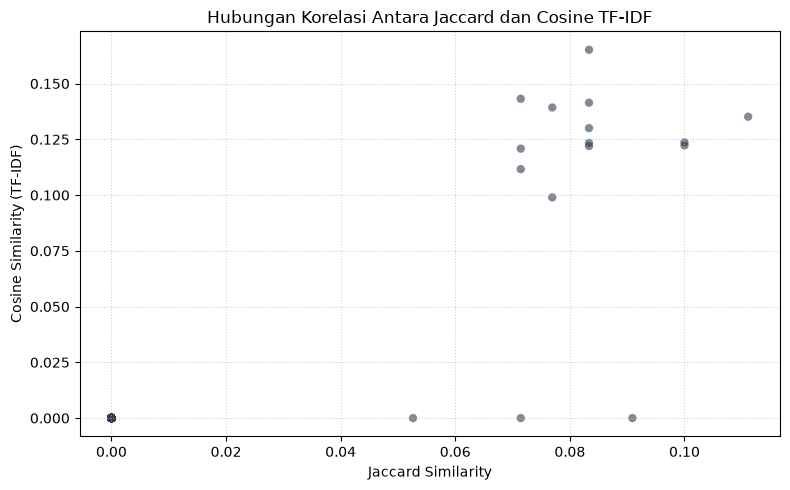

Nilai Korelasi Pearson antara Jaccard dan Cosine TF-IDF: 0.9069


In [9]:
plt.figure(figsize=(8, 5))
plt.scatter(pairs_df['jaccard'], pairs_df['cosine_tfidf'], alpha=0.6, color='#2c3e50', edgecolors='none')
plt.xlabel('Jaccard Similarity')
plt.ylabel('Cosine Similarity (TF-IDF)')
plt.title('Hubungan Korelasi Antara Jaccard dan Cosine TF-IDF')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

corr = pairs_df['jaccard'].corr(pairs_df['cosine_tfidf'])
print(f'Nilai Korelasi Pearson antara Jaccard dan Cosine TF-IDF: {corr:.4f}')

## 6. Pembahasan dan Analisis Perbandingan Metrik

Berdasarkan hasil eksperimen di atas, diperoleh beberapa temuan komparatif:

1. **Sifat Matematis dan Sensitivitas Panjang Dokumen:**
   - **Jaccard Similarity** beroperasi murni pada level himpunan kata unik tanpa memperhitungkan frekuensi kata berulang maupun bobot informatif korpus. Pada judul berita pendek dengan sedikit irisan kata, skor Jaccard cenderung sangat rendah (sparse).
   - **Cosine Similarity (Bag of Words)** memperhitungkan frekuensi kemunculan kata, namun kata-kata umum yang sering muncul dapat mendominasi produk skalar jika tidak difilter.
   - **Cosine Similarity (TF-IDF)** memberikan pembobotan lebih adil dengan mendiskon istilah yang terlalu sering muncul di banyak dokumen (IDF) dan mengapresiasi kata-kata diskriminatif, sehingga menghasilkan separasi kemiripan yang lebih tajam.

2. **Kesesuaian untuk Information Retrieval:**
   - Untuk sistem penelusuran kueri teks, Cosine TF-IDF menunjukkan performa seleksi yang paling relevan karena kata kunci spesifik seperti nama teknologi atau perangkat langsung memperoleh bobot tinggi, sedangkan Jaccard menghasilkan pembagian skor diskrit yang kurang peka terhadap kedalaman semantik kata.